# Faut-il mettre un peu de crypto dans un portefeuille classique ?

Le notebook précédent a montré que la crypto se comporte comme un actif risqué de plus,
lié à la bourse américaine mais bien plus volatil, pas comme une valeur refuge. La question pratique pour un investisseur est donc :
**ajouter un peu de Bitcoin à un portefeuille classique améliore-t-il quand même son couple
rendement / risque ?**

**Le portefeuille de référence** : le « 60/40 », c'est-à-dire 60 % d'actions et 40 % d'obligations,
le portefeuille standard de la gestion de patrimoine. On utilise des produits réellement achetables :

- **SPY** : ETF du S&P 500, dividendes réinvestis
- **TLT** : ETF d'obligations d'État US à long terme
- **BIL** : ETF de bons du Trésor à 1-3 mois, qui sert de placement sans risque pour le ratio de Sharpe

**Règles de simulation** : on revient aux poids cibles à la fin de chaque mois (rééquilibrage),
et chaque achat ou vente coûte 0,1 % de frais.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd

from src.analysis import charts, data
from src.analysis import portfolio as pf

pd.set_option("display.precision", 3)

returns = data.load_aligned("simple_return")
risk_free = returns["BIL"]
BASE = {"SPY": 0.6, "TLT": 0.4}


def simulate(weights, rebalance="M", rets=returns):
    return pf.backtest(rets, weights, rebalance)


def metrics(weights, rebalance="M", rets=returns):
    return pf.evaluate(simulate(weights, rebalance, rets)["valeur"], risk_free)


FORMATS = {
    "rendement_annuel": "{:+.1%}",
    "volatilite": "{:.1%}",
    "sharpe": "{:.2f}",
    "pire_baisse": "{:.1%}",
    "rendement_sur_pire_baisse": "{:.2f}",
}

years = (returns.index[-1] - returns.index[0]).days / 365.25
cash = (1 + risk_free).prod() ** (1 / years) - 1
print(f"Période : {returns.index.min():%d/%m/%Y} → {returns.index.max():%d/%m/%Y} ({years:.1f} ans)")
print(f"Rendement du placement sans risque (BIL) : {cash:.1%} par an")

Période : 03/01/2018 → 26/10/2026 (8.8 ans)
Rendement du placement sans risque (BIL) : 2.6% par an


## 1. Combien de crypto ?

On remplace une part croissante du 60/40 par du Bitcoin, de 0 à 20 %.

,rendement_annuel,volatilite,sharpe,pire_baisse,rendement_sur_pire_baisse
0% de Bitcoin,+7.9%,12.0%,0.48,-27.7%,0.29
1% de Bitcoin,+8.3%,12.1%,0.51,-28.0%,0.29
2% de Bitcoin,+8.6%,12.2%,0.53,-28.4%,0.30
3% de Bitcoin,+8.9%,12.3%,0.55,-28.8%,0.31
5% de Bitcoin,+9.6%,12.6%,0.59,-29.7%,0.32
10% de Bitcoin,+11.1%,13.9%,0.65,-32.7%,0.34
15% de Bitcoin,+12.6%,15.7%,0.68,-35.9%,0.35
20% de Bitcoin,+14.0%,17.9%,0.68,-39.1%,0.36


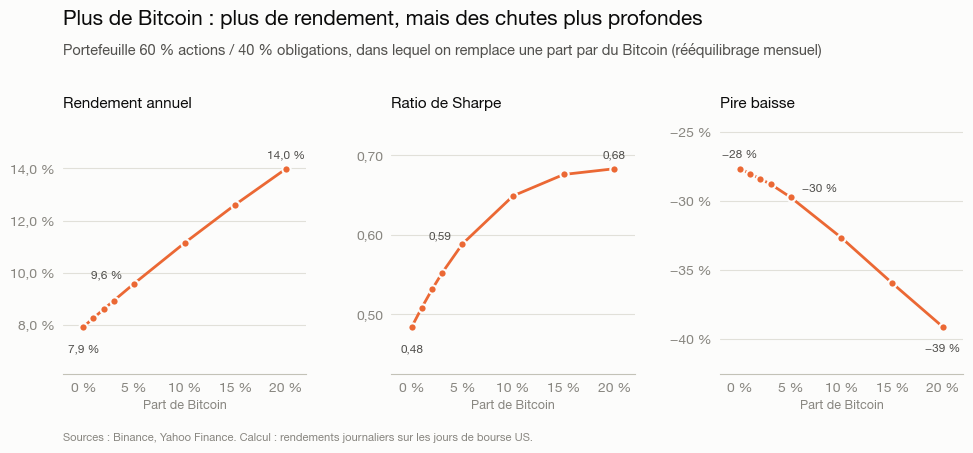

In [2]:
shares = [0, 0.01, 0.02, 0.03, 0.05, 0.10, 0.15, 0.20]
by_share = pd.DataFrame({x: metrics(pf.mix(BASE, {"BTC": x})) for x in shares}).T
fig = charts.allocation_curves(by_share, highlight=0.05)
_ = charts.save(fig, "08_part_de_bitcoin")
by_share.rename(index=lambda x: f"{x:.0%} de Bitcoin").style.format(FORMATS)

**À retenir**

- Chaque point de Bitcoin ajouté augmente le rendement **et** le ratio de Sharpe : sur cette période,
  le risque supplémentaire a été plus que rémunéré.
- Mais la pire baisse s'aggrave aussi à chaque étape : de -28 % sans Bitcoin à -39 % avec 20 %.
- Le gain de Sharpe ralentit nettement après 10 % : au-delà, on ajoute surtout du risque.

## 2. Comparer à risque égal

Ajouter du Bitcoin rend le portefeuille plus risqué. Une partie du gain vient-elle simplement
de là ? Pour le savoir, on le compare à un portefeuille **sans crypto mais avec plus d'actions**,
réglé pour avoir exactement la même volatilité.

In [3]:
with_btc = pf.mix(BASE, {"BTC": 0.05})
target_vol = metrics(with_btc)["volatilite"]
equity = pf.equity_share_for_volatility(returns, "SPY", "TLT", target_vol)
more_stocks = {"SPY": equity, "TLT": 1 - equity}

label_more_stocks = f"{equity * 100:.0f}/{(1 - equity) * 100:.0f} sans crypto"
compare = pd.DataFrame(
    {
        "60/40": metrics(BASE),
        label_more_stocks: metrics(more_stocks),
        "60/40 + 5 % Bitcoin": metrics(with_btc),
        "60/40 + 5 % Ethereum": metrics(pf.mix(BASE, {"ETH": 0.05})),
        "60/40 + 5 % or": metrics(pf.mix(BASE, {"GLD": 0.05})),
        "100 % actions": metrics({"SPY": 1.0}),
    }
).T
compare.style.format(FORMATS)

,rendement_annuel,volatilite,sharpe,pire_baisse,rendement_sur_pire_baisse
60/40,+7.9%,12.0%,0.48,-27.7%,0.29
65/35 sans crypto,+8.7%,12.6%,0.53,-27.1%,0.32
60/40 + 5 % Bitcoin,+9.6%,12.6%,0.59,-29.7%,0.32
60/40 + 5 % Ethereum,+10.0%,13.3%,0.59,-29.4%,0.34
60/40 + 5 % or,+8.2%,11.7%,0.52,-26.8%,0.31
100 % actions,+14.2%,19.0%,0.67,-33.7%,0.42


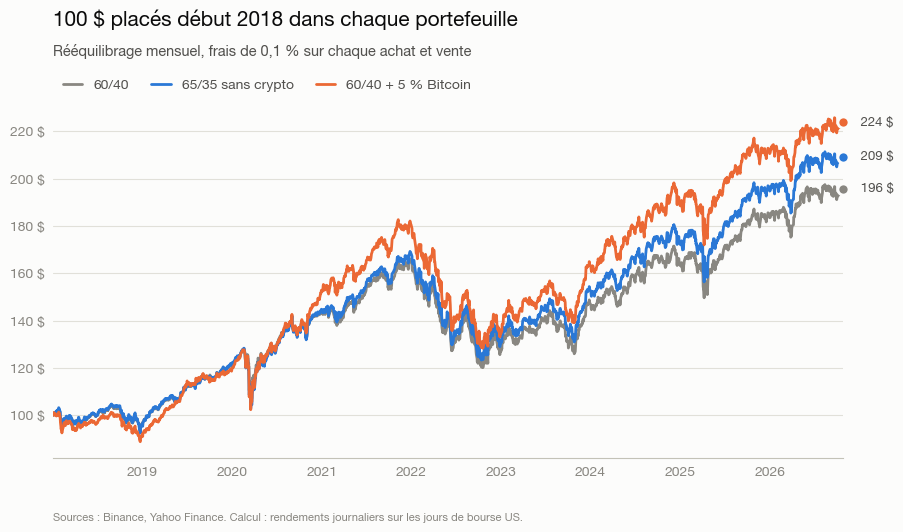

In [4]:
growth = pd.DataFrame(
    {
        "60/40": simulate(BASE)["valeur"],
        label_more_stocks: simulate(more_stocks)["valeur"],
        "60/40 + 5 % Bitcoin": simulate(with_btc)["valeur"],
    }
)
colors = {"60/40": charts.REFERENCE, label_more_stocks: charts.COLORS["SPY"], "60/40 + 5 % Bitcoin": charts.COLORS["BTC"]}
fig = charts.portfolio_growth(growth, colors)
_ = charts.save(fig, "09_croissance_portefeuilles")

**À retenir**

- **À volatilité égale**, ajouter 5 % de Bitcoin a mieux rapporté que prendre plus d'actions :
  environ 9,6 % par an contre 8,7 %. Le gain ne vient donc pas seulement d'un surplus de risque.
- **Mais la pire baisse est plus profonde** (-30 % contre -27 %) : la volatilité, mesure de risque
  « moyenne », ne capte pas les chutes brutales de la crypto.
- Ethereum donne un résultat proche du Bitcoin. L'or améliore un peu le Sharpe en **réduisant**
  le risque, là où la crypto l'améliore en augmentant le rendement.
- Sur cette période, les obligations longues ont perdu de l'argent (hausse des taux de 2022) :
  100 % actions a fait mieux que tous les portefeuilles diversifiés. C'est une particularité
  de la période, pas une règle.

## 3. D'où vient le risque ?

La **contribution au risque** mesure quelle part de la volatilité du portefeuille vient de chaque ligne.

,part du capital,part du risque
SPY,57.0%,72.6%
TLT,38.0%,15.3%
BTC,5.0%,12.1%


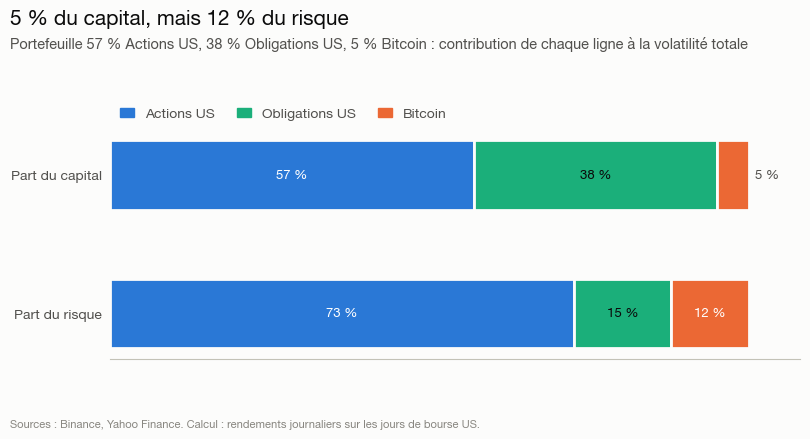

In [5]:
capital = pd.Series(with_btc)
risk = pf.risk_contribution(returns, with_btc)
fig = charts.capital_vs_risk(capital, risk)
_ = charts.save(fig, "10_capital_vs_risque")
pd.DataFrame({"part du capital": capital, "part du risque": risk}).style.format("{:.1%}")

**À retenir** : avec 5 % du capital, le Bitcoin porte environ **12 % du risque** du portefeuille.
Un investisseur qui pense « je ne mets que 5 % » prend en réalité beaucoup plus de risque que ça.

## 4. Faut-il rééquilibrer ?

,rendement_annuel,volatilite,sharpe,pire_baisse,rendement_sur_pire_baisse
mensuel,+9.6%,12.6%,0.59,-29.7%,0.32
trimestriel,+10.6%,12.6%,0.67,-30.0%,0.36
annuel,+10.2%,12.7%,0.63,-30.5%,0.33
jamais,+10.6%,14.0%,0.61,-31.7%,0.33


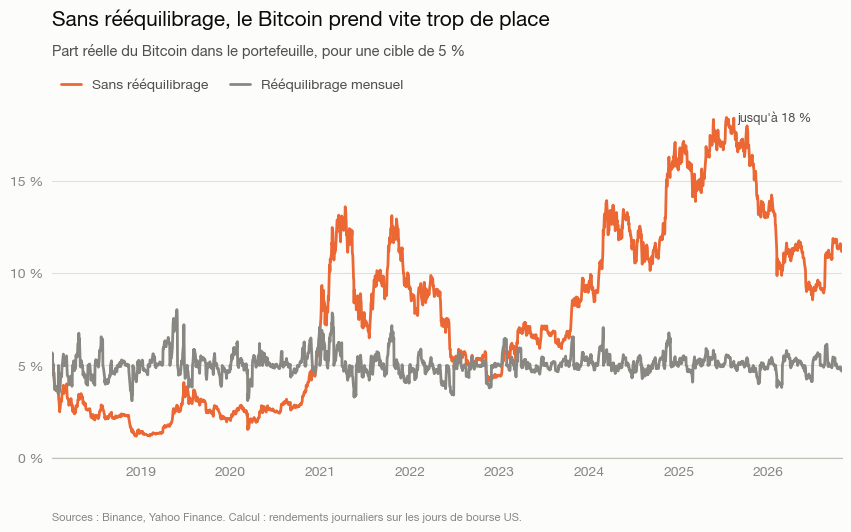

In [6]:
rebalancing = pd.DataFrame(
    {name: metrics(with_btc, freq) for name, freq in pf.REBALANCE.items()}
).T
drift = pd.DataFrame(
    {
        "Sans rééquilibrage": simulate(with_btc, None)["poids_BTC"],
        "Rééquilibrage mensuel": simulate(with_btc, "M")["poids_BTC"],
    }
)
fig = charts.weight_drift(drift, {"Sans rééquilibrage": charts.COLORS["BTC"],
                                  "Rééquilibrage mensuel": charts.REFERENCE}, target=0.05)
_ = charts.save(fig, "11_derive_des_poids")
rebalancing.style.format(FORMATS)

**À retenir**

- **Sans rééquilibrage**, la part du Bitcoin grimpe jusqu'à 18 % lors des envolées : on se retrouve
  avec un portefeuille bien plus risqué que prévu (volatilité 14 % au lieu de 12,6 %).
- Rééquilibrer garde le risque sous contrôle. Entre mensuel, trimestriel et annuel, les écarts de
  résultat dépendent surtout des hasards de cette période : on ne peut pas en tirer de règle générale.

## 5. Le résultat tient-il si on change la date de départ ?

Un résultat sur une seule période peut dépendre d'un départ chanceux. On rejoue donc le 60/40,
avec et sans 5 % de Bitcoin, sur **toutes les périodes de 3 ans** possibles, en démarrant chaque mois.

,résultat
périodes testées,70
Sharpe amélioré,100%
rendement amélioré,100%
pire baisse aggravée,100%
gain de Sharpe moyen,+0.17
aggravation moyenne de la pire baisse,-1.5%


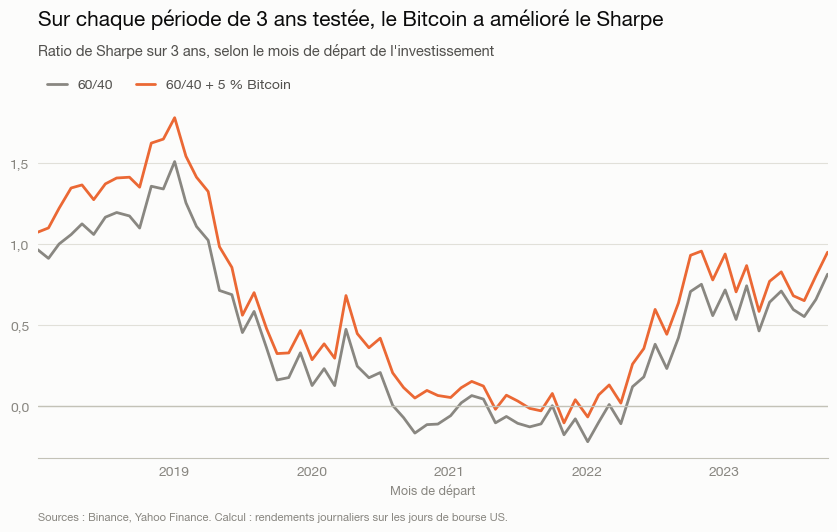

In [7]:
windows = pf.rolling_windows(returns, {"60/40": BASE, "60/40 + 5 % Bitcoin": with_btc}, risk_free, years=3)
pivot = windows.pivot(index="debut", columns="portefeuille")
fig = charts.rolling_sharpe(
    pivot["sharpe"][["60/40", "60/40 + 5 % Bitcoin"]],
    {"60/40": charts.REFERENCE, "60/40 + 5 % Bitcoin": charts.COLORS["BTC"]},
    years=3,
)
_ = charts.save(fig, "12_fenetres_3_ans")

diff = pivot.xs("60/40 + 5 % Bitcoin", axis=1, level=1) - pivot.xs("60/40", axis=1, level=1)
pd.Series(
    {
        "périodes testées": len(diff),
        "Sharpe amélioré": f"{(diff['sharpe'] > 0).mean():.0%}",
        "rendement amélioré": f"{(diff['rendement_annuel'] > 0).mean():.0%}",
        "pire baisse aggravée": f"{(diff['pire_baisse'] < 0).mean():.0%}",
        "gain de Sharpe moyen": f"{diff['sharpe'].mean():+.2f}",
        "aggravation moyenne de la pire baisse": f"{diff['pire_baisse'].mean():+.1%}",
    }
).to_frame("résultat")

**À retenir** : sur les 70 périodes de 3 ans testées, ajouter 5 % de Bitcoin a amélioré le Sharpe
**à chaque fois**, et aggravé la pire baisse **à chaque fois** (de 1,5 point en moyenne).
Attention : ces périodes se chevauchent et couvrent toutes la même histoire 2018-2026,
une période où le Bitcoin a fortement monté. Elles prouvent que le résultat ne dépend pas
du mois de départ, pas qu'il se répétera.

## 6. Et si le Bitcoin rapportait moins à l'avenir ?

C'est la vraie limite de toute l'analyse : le Bitcoin a fait **+21 % par an** sur la période.
On garde ses variations passées, jour par jour, mais on change son rendement moyen pour voir
à partir de quand l'ajouter ne sert plus à rien.

Rendement réel du Bitcoin : +21.3% par an
Seuil en dessous duquel 5 % de Bitcoin n'améliorent plus le Sharpe : -6.6% par an


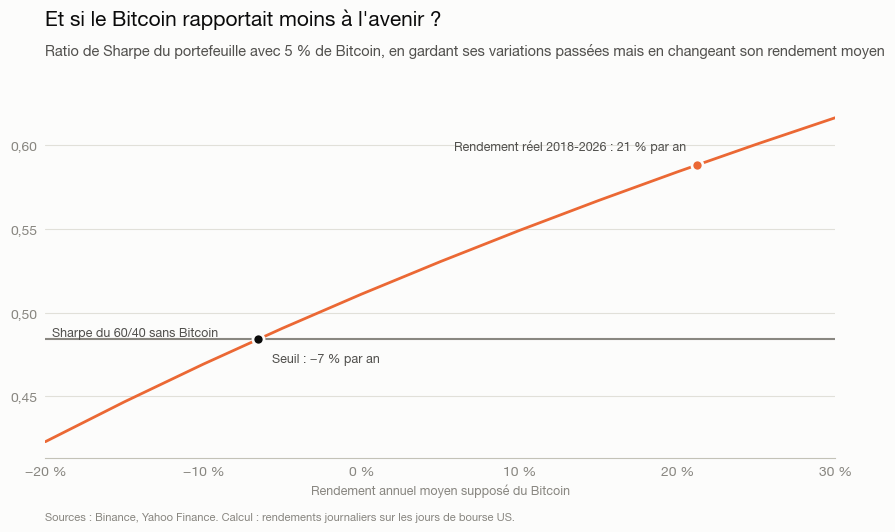

In [8]:
assumed = [-0.20, -0.15, -0.10, -0.05, 0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
sensitivity = pd.Series(
    {t: metrics(with_btc, rets=pf.with_annual_return(returns, "BTC", t))["sharpe"] for t in assumed}
)
actual = (1 + returns["BTC"]).prod() ** (1 / years) - 1
break_even = pf.break_even_return(returns, BASE, {"BTC": 0.05}, "BTC", risk_free)
fig = charts.return_sensitivity(sensitivity, reference=metrics(BASE)["sharpe"], actual=actual, break_even=break_even)
_ = charts.save(fig, "13_sensibilite_rendement")
print(f"Rendement réel du Bitcoin : {actual:+.1%} par an")
print(f"Seuil en dessous duquel 5 % de Bitcoin n'améliorent plus le Sharpe : {break_even:+.1%} par an")

**À retenir**

- Même avec un **rendement nul**, les 5 % de Bitcoin auraient encore amélioré le Sharpe. Le seuil
  se situe autour de **-7 % par an**.
- Pourquoi ? Grâce au **rééquilibrage** : le Bitcoin est si volatil et si peu lié aux obligations que
  revendre après ses hausses et racheter après ses baisses rapporte, même s'il fait du surplace.
- **La limite** : ce calcul garde la trajectoire passée du Bitcoin, faite de chutes suivies de remontées.
  Une crypto qui s'effondre sans jamais remonter (comme Terra-Luna en 2022) ne profite pas de cet effet :
  les 5 % sont simplement perdus.

## Conclusion

**Sur 2018-2026, une petite part de Bitcoin (autour de 5 %) a amélioré un portefeuille classique,
mais au prix de chutes plus profondes.**

| Question | Réponse |
|---|---|
| Le rendement ajusté du risque s'améliore-t-il ? | **Oui** : Sharpe de 0,48 à 0,59 avec 5 % de Bitcoin |
| Est-ce juste plus de risque ? | **Non** : à volatilité égale, il fait mieux que plus d'actions |
| Les chutes sont-elles pires ? | **Oui**, systématiquement : la volatilité sous-estime ce risque |
| Combien de risque pour 5 % de capital ? | Environ **12 %** du risque total |
| Le résultat dépend-il de la date de départ ? | **Non**, sur 70 périodes de 3 ans testées |
| Dépend-il du rendement futur du Bitcoin ? | **Assez peu**, tant qu'il ne perd pas plus de ~7 % par an et qu'on rééquilibre |

**Ce que ça ne dit pas** : l'avenir. Toute cette analyse porte sur un actif qui a survécu et fortement
monté (biais du survivant), sur moins de 9 ans d'histoire. Ce n'est pas un conseil d'investissement :
c'est la démonstration d'une méthode pour évaluer honnêtement un ajout à un portefeuille.